# River & Hydraulics Mesh Formats

`pyramids-mesh` is a **file-format reader**: it parses the many mesh file formats produced by
hydrodynamic and hydraulic models and returns a single, uniform in-memory object — a
`pyramids.netcdf.ugrid.UgridDataset`. Every mesh operation (connectivity, interpolation,
plotting) lives upstream in `pyramids`; this package only knows how to *read the files*.

This tutorial walks through the **river / flood 2D hydraulic and interchange** formats. For each
one we follow the same four steps:

1. a short note on **what the format is**,
2. **read** it with `UgridDataset.read_file(path, driver="<name>")`,
3. inspect it with `ds.summary()` (a pandas table of every variable),
4. **plot** it and interpret what we see.

The whole point is that one API — `read_file` plus `summary`/`plot` — covers formats as different
as an ASCII SMS mesh, a TELEMAC binary, an ESRI TIN directory and an HEC-RAS HDF5 plan file.

## Setup

`import pyramids` (pulled in by `from pyramids.netcdf.ugrid import ...`) must come first — it is
what puts the vendored GDAL on `sys.path`. We force a non-interactive matplotlib backend so the
figures render and **embed** into the notebook, and point `DATA` at the repository's
`examples/data/` directory (paths are relative to *this notebook*, two levels down).

One practical wrinkle: `pyramids`/`cleopatra` force the Agg backend on import and inside every `plot` call, so a plain `plt.show()` will not embed a figure under `nbconvert`. We define a tiny `show()` helper that rasterises the current figure to a PNG and displays it — the figures below are produced with it.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")
print("data dir exists:", DATA.resolve().exists())

import io
from IPython.display import Image, display


def show():
    """Embed the current figure as a PNG.

    cleopatra switches matplotlib to the Agg backend inside every ``plot`` call, so a plain
    ``plt.show()`` cannot render inline here. We rasterise the current figure explicitly
    instead, which embeds reliably under nbconvert regardless of the active backend.
    """
    fig = plt.gcf()
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight", dpi=110)
    plt.close(fig)
    display(Image(data=buf.getvalue()))

data dir exists: True


A note on coordinate reference systems: most of these mesh formats store only raw
`(x, y)` numbers with **no embedded CRS**, so `ds.crs` will usually be `None`. That is expected —
the model that wrote the file knew its own projection, but the format has nowhere to record it.
You attach a CRS downstream in `pyramids` when you need one.

## Part 1 — Geometry & interchange meshes

These formats carry a **topology** (nodes + faces) and usually a bed elevation `node_z`, but no
time-varying results. They are how a mesh is handed between tools.

### 2DM — Aquaveo SMS

`.2dm` is the Surface-water Modeling System mesh: an ASCII list of `ND` (nodes) and `E3T`/`E4Q`
(triangular/quad elements). It is the lingua-franca 2D mesh of the US hydraulic world (SRH-2D,
TUFLOW, HEC-RAS all import it). Our sample also carries a `material` id per element.

In [2]:
ds_2dm = UgridDataset.read_file(str(DATA / "minimal.2dm"), driver="2dm")
print("nodes:", ds_2dm.n_node, " faces:", ds_2dm.n_face, " crs:", ds_2dm.crs)
ds_2dm.summary()

nodes: 4  faces: 2  crs: None


C:\python-environments\pixi\envs\pyramids-mesh-4081970794675243037\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'dfsu' (pyramids_mesh.drivers.dhi:DfsuDriver) could not be loaded and was skipped: ModuleNotFoundError("No module named 'mikeio'")
  driver = _instantiate(entry_point)


,count,min,max,mean,std
variable,,,,,
material,2,1.0,1.0,1.0,0.0
node_z,4,0.0,0.0,0.0,0.0


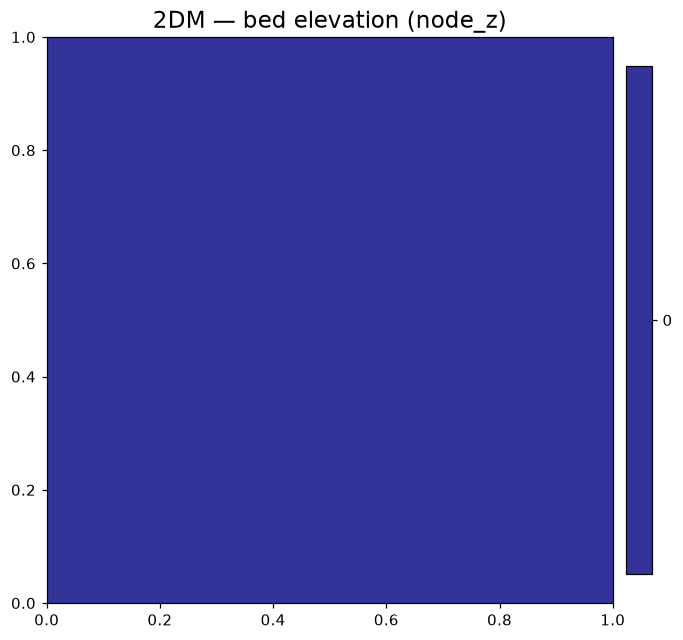

In [3]:
ds_2dm.plot("node_z", cmap="terrain", colorbar=True, title="2DM — bed elevation (node_z)")
show()

The mesh is a tiny two-triangle square; `node_z` is the bed level carried on the nodes. The
`summary()` table lists both `material` (an integer zone id) and `node_z` with their min/max/mean —
the uniform statistics view we get for *every* format below.

### Mike21 — DHI `.mesh`

DHI's ASCII `.mesh` file is the mesh frame for the MIKE 21 flexible-mesh engine: a node table with
a boundary code, then the element table. It is geometry only — results live in the separate
(binary `.dfsu`) files we cover at the end.

In [4]:
ds_m21 = UgridDataset.read_file(str(DATA / "minimal.mesh"), driver="mike21")
print("nodes:", ds_m21.n_node, " faces:", ds_m21.n_face)
ds_m21.summary()

nodes: 4  faces: 2


,count,min,max,mean,std
variable,,,,,
node_z,4,0.0,0.0,0.0,0.0


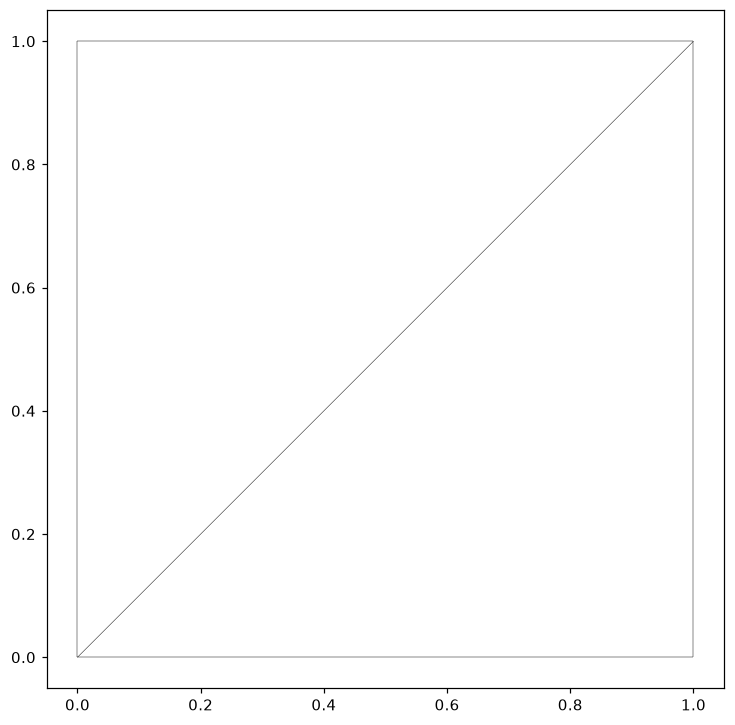

In [5]:
ds_m21.plot_outline()
show()

With only `node_z` and a handful of elements, `plot_outline()` is the clearest view: it draws
the face edges so you can see the mesh connectivity itself rather than a data field.

### PLY — Stanford polygon, and *computing* a face field

`.ply` is the generic Stanford polygon format (common for 3D surfaces and exported meshes). Our
sample is pure geometry — only `node_z`. This is a good moment to show that once a file is read,
the full `pyramids` mesh toolkit is available: `ds.mesh` exposes derived geometry such as
`face_areas` and `face_centroids` (shape `(2, n_face)`). We compute the per-face area and
**attach it as a new face-located variable** with `with_variable`, then colour by it.

In [6]:
ds_ply = UgridDataset.read_file(str(DATA / "minimal.ply"), driver="ply")
areas = np.asarray(ds_ply.mesh.face_areas)          # one value per face
print("face_areas:", areas, " centroids shape:", np.asarray(ds_ply.mesh.face_centroids).shape)
ds_ply = ds_ply.with_variable("face_area", areas, location="face")
ds_ply.summary()

face_areas: [0.5 0.5]  centroids shape: (2, 2)


,count,min,max,mean,std
variable,,,,,
node_z,4,2.0,3.5,2.75,0.559017
face_area,2,0.5,0.5,0.50,0.000000


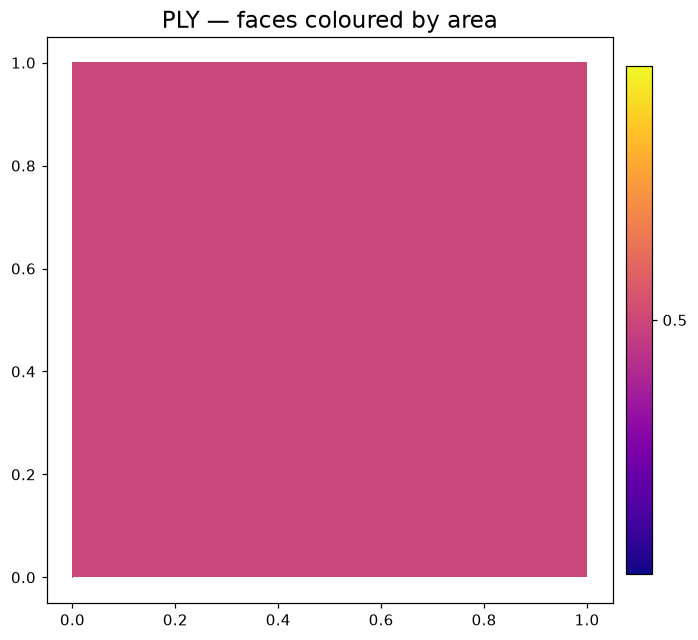

In [7]:
ds_ply.plot("face_area", cmap="plasma", colorbar=True, title="PLY — faces coloured by area")
show()

`face_area` did not exist in the file — we derived it from the topology and attached it. This
is the division of labour the package is built around: **pyramids-mesh reads the file, pyramids
does the geometry.** For a geometry-only mesh a computed field like area (or a centroid-based
value) gives you something meaningful to colour.

### XMS TIN — SMS triangulated irregular network

`.tin` is the SMS TIN: an ASCII triangulated irregular network, the surface you build a 2D mesh
*from*. Driver name `xmstin`. It is nodes with elevation plus triangle connectivity.

In [8]:
ds_tin = UgridDataset.read_file(str(DATA / "minimal.tin"), driver="xmstin")
print("nodes:", ds_tin.n_node, " triangles:", ds_tin.n_face)
ds_tin.summary()

nodes: 4  triangles: 2


,count,min,max,mean,std
variable,,,,,
node_z,4,2.0,3.5,2.75,0.559017


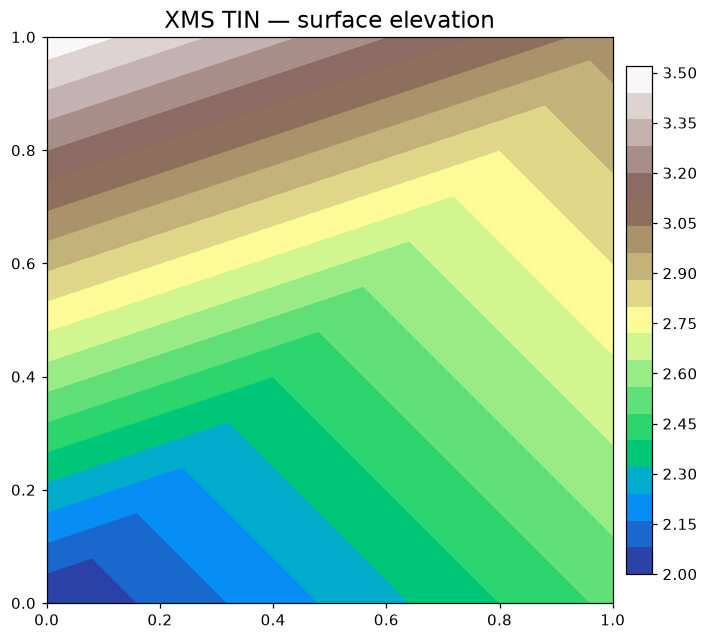

In [9]:
ds_tin.plot("node_z", cmap="terrain", colorbar=True, title="XMS TIN — surface elevation")
show()

A TIN is always triangles, and the payload is the surface elevation on the nodes — exactly
what you would drape a river bathymetry over before meshing.

### ESRI TIN — a *directory* of `.adf` files

An ESRI TIN is not a single file: it is a **directory** of binary `.adf` tables (`tnod`, `tedg`,
`tnxy`, `tnz`, ...). You therefore pass the directory path and `driver="esri_tin"`. This sample is
a real DEM TIN with a few hundred triangles — large enough to actually look like terrain.

In [10]:
ds_esri = UgridDataset.read_file(str(DATA / "esri_tin" / "dem"), driver="esri_tin")
print("nodes:", ds_esri.n_node, " triangles:", ds_esri.n_face)
ds_esri.summary()

nodes: 281  triangles: 528


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 528 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


,count,min,max,mean,std
variable,,,,,
node_z,281,-3.402823e+38,240.444153,-4.843877e+36,4.030909e+37


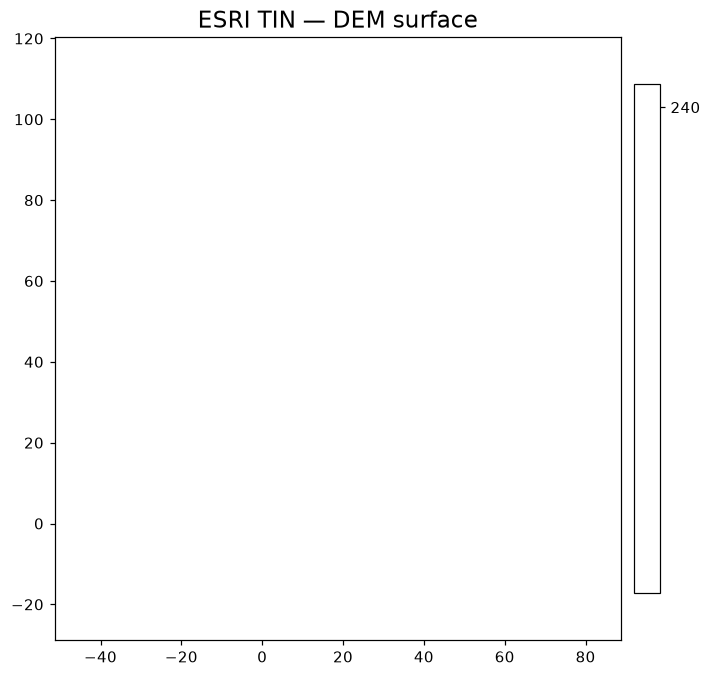

In [11]:
ds_esri.plot("node_z", cmap="terrain", colorbar=True, title="ESRI TIN — DEM surface")
show()

The reader also emits a warning that it reversed some clockwise faces to a consistent
counter-clockwise winding — a normalisation step so downstream code sees one orientation. The plot
is a proper little terrain surface, the kind of DEM you would carve a channel into.

## Part 2 — Hydraulic model results

These formats carry **real simulation results** — water depth, water-surface elevation, velocity —
on top of the mesh. For each we plot an actual result variable, not just the geometry.

### Selafin / SERAFIN — TELEMAC

`.slf` is the Selafin (a.k.a. SERAFIN) binary used by the TELEMAC-MASCARET suite for 2D
hydrodynamics. It stores the triangular mesh plus time-stepped result arrays; here `WATER DEPTH`.

In [12]:
ds_slf = UgridDataset.read_file(str(DATA / "minimal.slf"), driver="selafin")
print("variables:", ds_slf.data_variable_names)
ds_slf.summary()

variables: ['WATER DEPTH']


,count,min,max,mean,std
variable,,,,,
WATER DEPTH,8,0.125,1.75,0.90625,0.554632


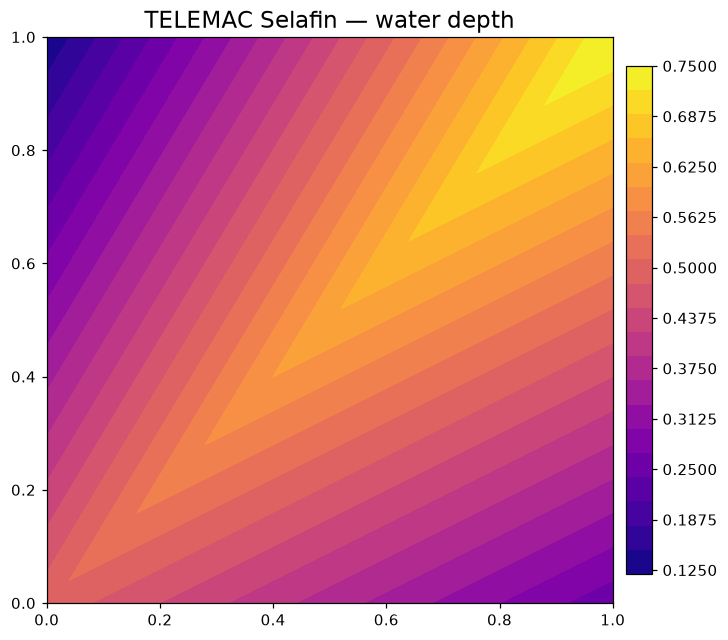

In [13]:
ds_slf.plot("WATER DEPTH", cmap="plasma", colorbar=True, title="TELEMAC Selafin — water depth")
show()

`WATER DEPTH` is a genuine hydraulic result field carried on the mesh nodes — the quantity a
TELEMAC 2D run solves for.

### SWW — ANUGA

`.sww` is ANUGA's NetCDF output (ANUGA is a shallow-water flood model). It stores bed elevation
(`node_z`) and the free-surface `stage`, among others.

In [14]:
ds_sww = UgridDataset.read_file(str(DATA / "minimal.sww"), driver="sww")
print("variables:", ds_sww.data_variable_names)
ds_sww.summary()

variables: ['node_z', 'stage']


,count,min,max,mean,std
variable,,,,,
node_z,4,2.000,3.50,2.75000,0.559017
stage,8,0.125,1.75,0.90625,0.554632


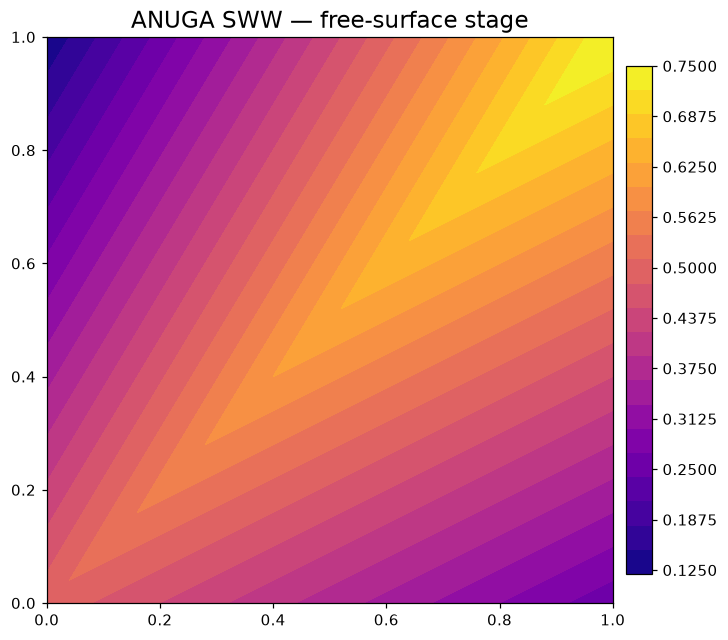

In [15]:
ds_sww.plot("stage", cmap="plasma", colorbar=True, title="ANUGA SWW — free-surface stage")
show()

`stage` is the water-surface elevation (bed + depth). Comparing `stage` to `node_z` in the
summary table is how you read off the water depth of an ANUGA flood result.

### SRH-2D — Aquaveo / USACE

SRH-2D ships a trio: `.srhgeom` (the mesh), `.srhhydro` (the control deck) and `.srhmat` (material
zones). We read the geometry file; the driver folds in the material and Manning's-n fields it can
find. This is the public-domain USACE *Muncie* example — a real ~19 000-element river mesh.

In [16]:
ds_srh = UgridDataset.read_file(str(DATA / "srh2d" / "Muncie.srhgeom"), driver="srh2d")
print("nodes:", ds_srh.n_node, " faces:", ds_srh.n_face, " vars:", ds_srh.data_variable_names)
ds_srh.summary()

nodes: 21520  faces: 19407  vars: ['material', 'manning_n', 'node_z']


,count,min,max,mean,std
variable,,,,,
material,19407,2.00000,7.00000,4.884062,1.615723
manning_n,19407,0.03000,0.06000,0.049040,0.008832
node_z,21520,913.78125,974.84375,943.094422,9.414194


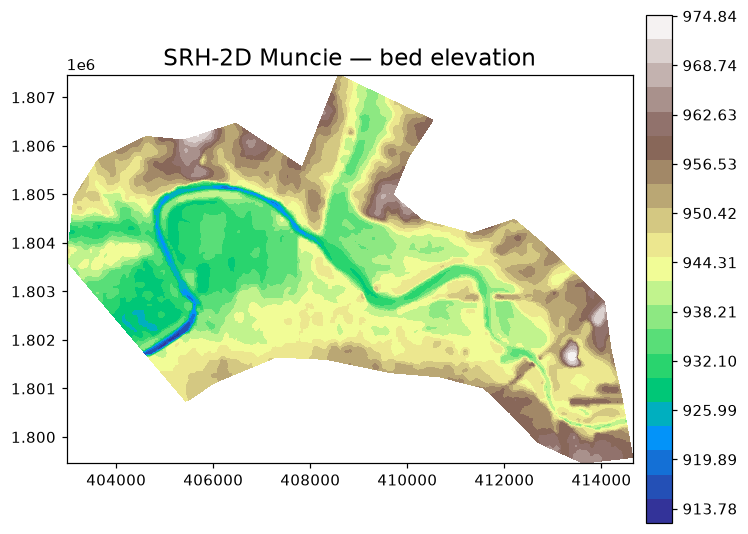

In [17]:
ds_srh.plot("node_z", cmap="terrain", colorbar=True, title="SRH-2D Muncie — bed elevation")
show()

At ~19 000 mixed triangle/quad/polygon elements this is the first mesh that looks like a real
river reach. `node_z` reveals the channel bathymetry threading through the floodplain; `material`
and `manning_n` (in the table) are the roughness zones the solver uses.

### HEC-RAS 2D — USACE HDF5 plan file

HEC-RAS stores a 2D run in an HDF5 **plan file** (`.p**.hdf`). The driver reads the first 2D flow
area's mesh plus its **summary results** — the maximum and minimum water-surface rasters. This is
the USACE *Bald Eagle Creek Dam Break* example.

In [18]:
ds_ras = UgridDataset.read_file(str(DATA / "hecras" / "BaldEagleDamBrk.p18.hdf"), driver="hecras")
print("nodes:", ds_ras.n_node, " cells:", ds_ras.n_face, " vars:", ds_ras.data_variable_names)
ds_ras.summary()

nodes: 3937  cells: 3359  vars: ['Maximum Water Surface', 'Minimum Water Surface']


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\drivers\hecras.py:200: UserWarning: '..\\..\\examples\\data\\hecras\\BaldEagleDamBrk.p18.hdf' holds 2 2D flow areas ['BaldEagleCr', 'Upper 2D Area']; only the first ('BaldEagleCr') is read -- selecting another is not wired yet
  area = self._select_area(areas)


,count,min,max,mean,std
variable,,,,,
Maximum Water Surface,3359,537.211121,764.279785,587.039248,31.895550
Minimum Water Surface,3359,527.152527,764.279785,578.899219,36.926533


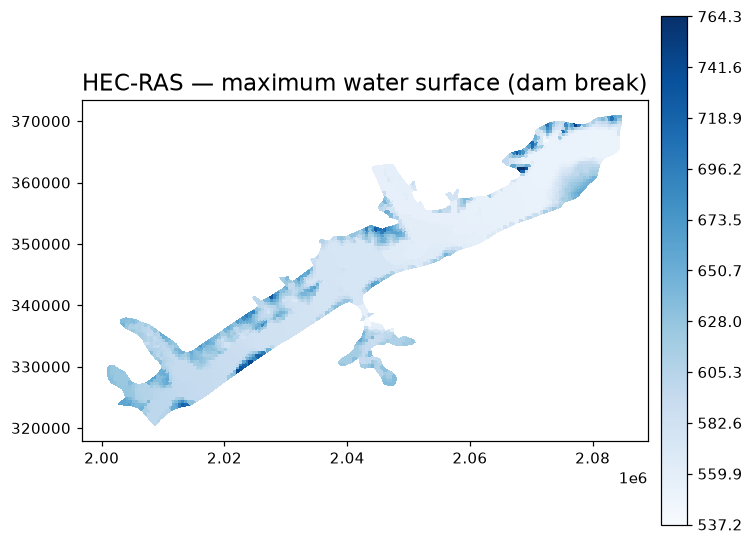

In [19]:
ds_ras.plot("Maximum Water Surface", cmap="Blues", colorbar=True,
            title="HEC-RAS — maximum water surface (dam break)")
show()

The file holds two flow areas; the driver warns that it reads the first (`BaldEagleCr`) and
plots its **maximum water surface** — the peak flood envelope of the dam-break run. This is a
results field defined per cell (`n_face` values), not per node.

### FLO-2D — HDF5 time series + `.OUT`

FLO-2D PRO writes `TIMDEP.HDF5` (time-dependent `FLOW DEPTH`, `Velocity MAG`, ...) alongside ASCII
`.OUT` summaries. The driver reconstructs the grid from the element coordinates and exposes both
the per-element maxima and the time-varying arrays.

In [20]:
ds_flo = UgridDataset.read_file(str(DATA / "flo2d" / "TIMDEP.HDF5"), driver="flo2d")
print("cells:", ds_flo.n_face, " vars:", ds_flo.data_variable_names)
ds_flo.summary()

cells: 240  vars: ['max_floodplain_depth', 'FLOW DEPTH', 'Floodplain Water Surface Elevation', 'Velocity MAG']


,count,min,max,mean,std
variable,,,,,
max_floodplain_depth,240,0.0615,0.408400,0.300830,0.085927
FLOW DEPTH,144000,0.0000,7.015525,6.510067,1.243974
Floodplain Water Surface Elevation,144000,0.0000,15.865525,10.951316,2.910526
Velocity MAG,144000,0.0000,7.510303,5.226126,1.224978


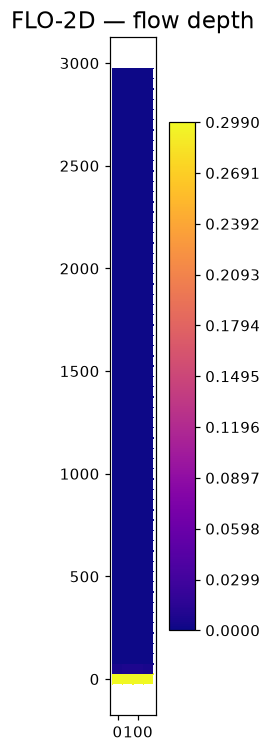

In [21]:
ds_flo.plot("FLOW DEPTH", cmap="plasma", colorbar=True, title="FLO-2D — flow depth")
show()

This is a 240-element flume (4 × 60 cells). `FLOW DEPTH` is the simulated inundation depth;
`max_floodplain_depth` (from the companion `.OUT`) is its envelope. FLO-2D is a quadtree/grid model,
so the cells are regular squares rather than the triangles we saw above.

### TUFLOW FV — flexible-mesh NetCDF

TUFLOW FV writes its flexible-mesh results to NetCDF. The file carries instantaneous fields
(`D` depth, `H` water level, `V_x`/`V_y` velocity) and their maxima (`max_D`, `max_H`, ...).

In [22]:
ds_fv = UgridDataset.read_file(str(DATA / "tuflowfv" / "Cone_003.nc"), driver="tuflowfv")
print("cells:", ds_fv.n_face, " vars:", ds_fv.data_variable_names[:8], "...")
ds_fv.summary(variables=["D", "H", "max_D", "ZB"])

cells: 2866  vars: ['D', 'H', 'V_x', 'V_y', 'ZB', 'max_D', 'max_H', 'max_V_x'] ...


,count,min,max,mean,std
variable,,,,,
D,45856,1.192093e-07,2.007636,0.050759,0.196749
H,45856,1.205051e+00,97.256538,33.132943,23.417905
max_D,2844,1.003401e-02,2.007636,0.121414,0.367166
ZB,45856,1.205051e+00,97.219559,33.082184,23.449038


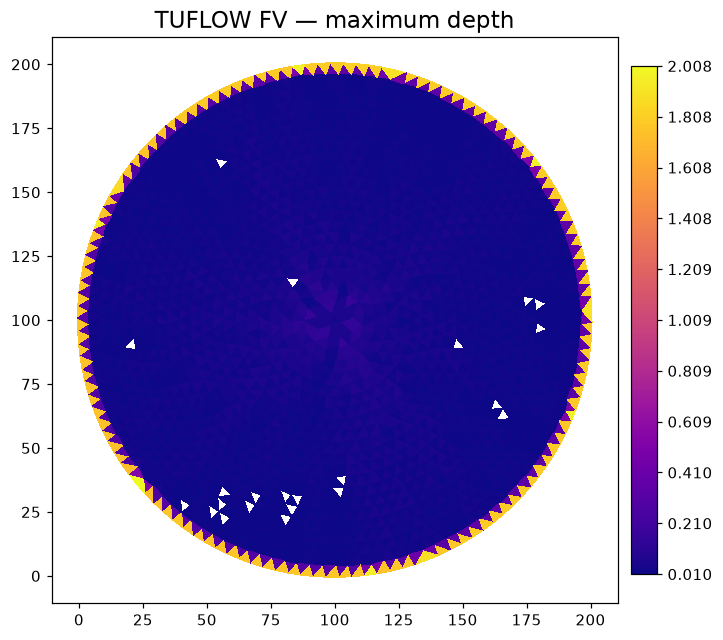

In [23]:
ds_fv.plot("max_D", cmap="plasma", colorbar=True, title="TUFLOW FV — maximum depth")
show()

Here we pass `variables=[...]` to `summary()` to focus the table on a few fields rather than
all sixteen. `max_D` is the peak depth over the run — the classic flood-hazard output — on a radial
"cone" test mesh.

### 3Di — a `needs_mesh` results reader that stands alone

3Di writes NetCDF results, but **not** as a plain node-list + connectivity: each 2D cell is stored
by its centre and size, so the reader has to *reconstruct* the quad mesh from cell geometry. It is
registered as a `needs_mesh` / results driver (see Part 3), yet because the results file embeds
enough to rebuild the grid, it **can** be opened on its own — no companion mesh needed.

In [24]:
ds_3di = UgridDataset.read_file(str(DATA / "3di" / "results_3di.nc"), driver="3di")
print("cells:", ds_3di.n_face, " vars:", ds_3di.data_variable_names)
ds_3di.summary(variables=["Mesh2D_s1", "Mesh2D_vol"])

cells: 16  vars: ['Mesh2D_q_lat', 'Mesh2D_rain', 'Mesh2D_s1', 'Mesh2D_su', 'Mesh2D_ucx', 'Mesh2D_ucy', 'Mesh2D_vol']


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:483: UserWarning: '..\\..\\examples\\data\\3di\\results_3di.nc' also carries a coupled 1D network (Mesh1D*), which pyramids cannot represent alongside the 2D mesh: there is no Network1d coupling relation, so the 1D part is not in this result
  parsed = self._parse(path, lazy=lazy)


,count,min,max,mean,std
variable,,,,,
Mesh2D_s1,112,-9999.0,0.020815,-1428.424310,3498.922874
Mesh2D_vol,112,0.0,0.749338,0.153423,0.158231


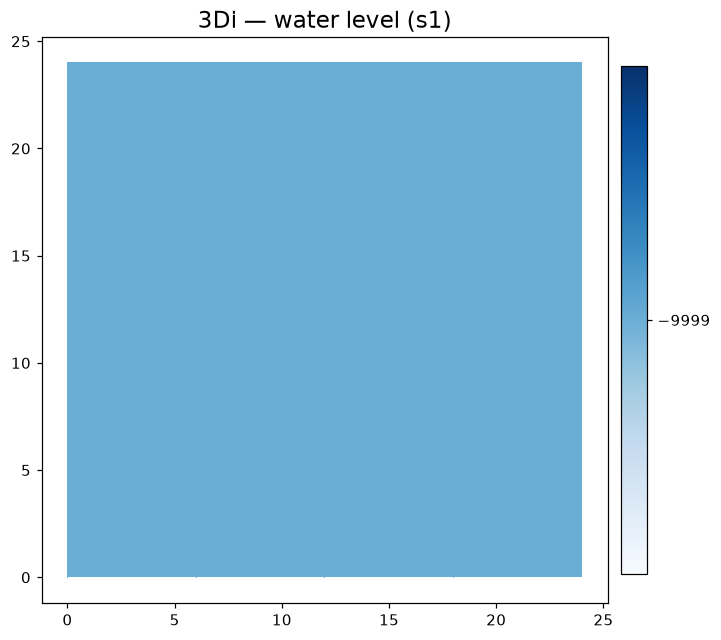

In [25]:
ds_3di.plot("Mesh2D_s1", cmap="Blues", colorbar=True, title="3Di — water level (s1)")
show()

The reader warns that the file *also* holds a coupled 1D network it cannot represent beside
the 2D mesh, so only the 2D part is returned. `Mesh2D_s1` is the 2D water level — a real result on
the reconstructed quad cells.

### XDMF — meshio time series

`.xdmf` is an XML "light-data" header that points at heavy arrays in a sibling `.h5` file. It is a
generic scientific-mesh container (here written by `meshio`) holding a 5-step temporal collection
with per-step fields `phi`, `u`, `a`.

In [26]:
ds_xdmf = UgridDataset.read_file(str(DATA / "xdmf" / "out.xdmf"), driver="xdmf")
print("variables:", ds_xdmf.data_variable_names)
ds_xdmf.summary()

variables: ['phi', 'a']


,count,min,max,mean,std
variable,,,,,
phi,20,0.0,1.0,0.5,0.353553
a,10,3.0,4.2,3.6,0.600000


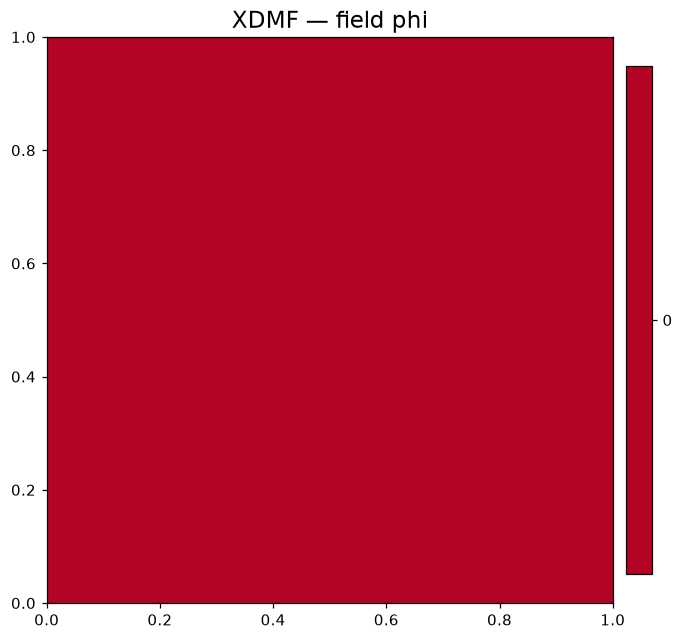

In [27]:
ds_xdmf.plot("phi", cmap="viridis", colorbar=True, title="XDMF — field phi")
show()

The driver follows the XML pointer into `out.h5` transparently — you read `out.xdmf` and get
the arrays. `phi` is one of the time-varying fields; `summary()` reduces it over the whole series.

## Part 3 — Results-only formats: the `needs_mesh` concept

Some formats store **only values, no geometry** — a column of numbers, one per cell or node, that
is meaningless without the mesh it was computed on. The registry marks these drivers `needs_mesh`.
Trying to open such a file on its own raises `UnsupportedMeshFormatError` with a clear instruction:
read the mesh first, then **attach** the values with `ds.attach_data(results_path)`.

So the pattern is two lines:

```python
mesh = UgridDataset.read_file("model.2dm")       # topology (+ bed)
result = mesh.attach_data("model.dat")           # values bolted onto that mesh
```

We demonstrate it with the two results-only formats in this dataset: **XMDF** and **SMS DAT**.

### XMDF — SMS HDF5 results

`.xmdf` is the SMS HDF5 result container (depths, velocities, dt). It carries values but no mesh,
so on its own it cannot be opened. Here the companion mesh is the `minimal.2dm` sitting beside it;
we read that, then attach the XMDF results.

In [28]:
mesh_xmdf = UgridDataset.read_file(str(DATA / "xmdf" / "minimal.2dm"))
print("mesh only:", mesh_xmdf.data_variable_names)
ds_xmdf = mesh_xmdf.attach_data(str(DATA / "xmdf" / "minimal.xmdf"))
print("after attach:", ds_xmdf.data_variable_names)
ds_xmdf.summary()

mesh only: ['material', 'node_z']
after attach: ['material', 'node_z', 'Minimum dt', 'Minimum dt_active']


,count,min,max,mean,std
variable,,,,,
material,16,1.0,1.000000,1.000000,0.000000
node_z,25,0.0,0.000000,0.000000,0.000000
Minimum dt,75,0.0,0.319275,0.191565,0.156412
Minimum dt_active,48,1.0,1.000000,1.000000,0.000000


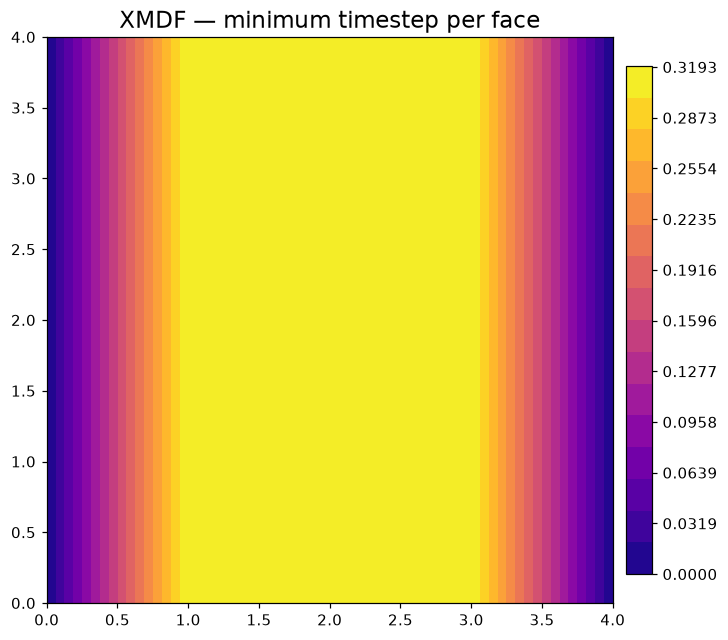

In [29]:
ds_xmdf.plot("Minimum dt", cmap="plasma", colorbar=True, title="XMDF — minimum timestep per face")
show()

Reading the mesh gave us `material` and `node_z`; `attach_data` added the XMDF result fields
(here a `Minimum dt` diagnostic). The values are now carried on the same mesh and plot like any
other field. Opening the `.xmdf` alone would have raised `UnsupportedMeshFormatError` — the mesh is
mandatory.

### SMS DAT — ASCII results

`.dat` is the SMS ASCII result file (a scalar/vector time series over an SMS mesh). Same story: it
is results-only, so we attach it to its `minimal.2dm` mesh rather than opening it directly.

In [30]:
mesh_dat = UgridDataset.read_file(str(DATA / "minimal.2dm"))
ds_dat = mesh_dat.attach_data(str(DATA / "minimal.dat"))
print("after attach:", ds_dat.data_variable_names)
ds_dat.summary()

after attach: ['material', 'node_z', 'depth']


,count,min,max,mean,std
variable,,,,,
material,2,1.0,1.0,1.00,0.000000
node_z,4,0.0,0.0,0.00,0.000000
depth,8,0.5,1.8,1.15,0.512348


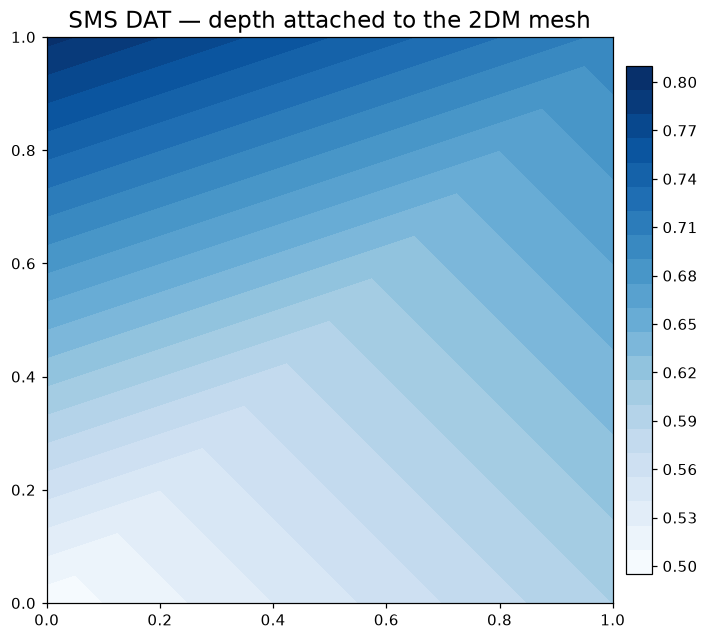

In [31]:
ds_dat.plot("depth", cmap="Blues", colorbar=True, title="SMS DAT — depth attached to the 2DM mesh")
show()

`attach_data` read the `.dat` column and bound it to the mesh as a `depth` field. This is why
`dat` and `xmdf` are `needs_mesh` drivers: the file alone is just numbers; it only becomes a map
once it sits on a mesh.

## A note on DFSU (not shown here)

DHI's **`.dfsu`** flexible-mesh result format (the binary companion to the `.mesh` we read above)
needs the optional **`mikeio`** dependency, which is *not* installed in this notebook's
environment. It is therefore an **optional-extra driver**: install the `dhi` extra and it registers
automatically. CI exercises it in a dedicated `dhi` environment, so the `dfsu` reader is tested —
just not here. (You may have noticed the harmless startup warning that the `dfsu` driver was
skipped because `mikeio` is missing.)

## Summary

One API — `UgridDataset.read_file(path, driver=...)` — read **14** different river/flood formats
into the same object, and `summary()` / `plot()` worked uniformly across all of them:

| Group | Formats | What we plotted |
|---|---|---|
| Geometry / interchange | 2DM, Mike21 `.mesh`, PLY, XMS TIN, ESRI TIN | bed `node_z` (and a *computed* `face_area` for PLY) |
| Hydraulic results | Selafin, SWW, SRH-2D, HEC-RAS, FLO-2D, TUFLOW FV, 3Di, XDMF | real result fields (depth, water surface, max depth) |
| Results-only (`needs_mesh`) | XMDF, SMS DAT | values **attached** to a companion 2DM mesh |
| Optional extra (not shown) | DFSU | needs `mikeio`; covered by CI's `dhi` env |

Takeaways:

- **pyramids-mesh reads files; pyramids does the geometry.** Derived quantities like `face_areas`
  came from `ds.mesh`, and we attached a computed field with `with_variable`.
- **`needs_mesh` formats** (XMDF, DAT) carry only values — read the mesh first, then `attach_data`.
  3Di is a `needs_mesh` driver that happens to reconstruct its own grid, so it opens standalone.
- **CRS is almost always `None`** — these formats store bare coordinates; you set the projection
  downstream in `pyramids`.